# 02 · Búsqueda semántica y recuperación híbrida

El módulo 01 terminó con BM25 fallando en preguntas que *significan* lo mismo que un pasaje pero usan palabras
distintas. La solución es la **búsqueda semántica**: convertir cada texto en un vector de números (un **embedding**) de
modo que los textos de significado parecido queden cerca, y buscar por distancia. Este módulo la construye, la mide
frente a BM25 en tres tipos de pregunta y muestra un resultado que sorprende a muchos: **ninguno gana en todo, y una
combinación ingenua 50/50 tampoco gana automáticamente.** Combinarlos (*recuperación híbrida*) es lo que usa el
asistente de chat supervisado que se construye en este proyecto, pero los pesos importan, y solo se descubre midiendo.

**Aprenderás**
1. Qué es un embedding y cómo funciona la búsqueda por similitud (similitud del coseno)
2. Ejecutar un modelo de embeddings pequeño en la CPU de un portátil
3. Dónde la búsqueda semántica supera a BM25 (paráfrasis) y dónde pierde (códigos y nombres exactos)
4. Reciprocal Rank Fusion, la forma simple y robusta de fusionar dos ordenaciones
5. Calibrar cuándo negarse a responder con puntuaciones de embeddings
6. Cuándo empieza a importar un *índice* vectorial (FAISS y similares), medido

## 1. El corpus y la línea base BM25

El mismo manual de Harbourview del módulo 01 (copiado aquí para que el notebook se baste solo) y el mismo BM25 que
escribimos allí. Además de las 14 preguntas con respuesta del módulo 01, añadimos dos conjuntos nuevos con los que
ningún método se ajustó:

* **Paráfrasis**: diez preguntas escritas como las haría de verdad un compañero, que comparten pocas palabras con el
  manual ("Are boats cancelled when the sea is too rough?").
* **Identificadores**: cinco preguntas sobre códigos y nombres exactos (`PF-203`, `YW-110`, `OSS1`...).

In [1]:
# El manual de Harbourview: 22 pasajes, ficticios, escritos para este curso
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, pregunta, pasaje correcto, dato que debe contener la respuesta); None = el manual no lo dice
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [2]:
import re, math, time
import numpy as np
import matplotlib.pyplot as plt

PARAPHRASES = [
    ("r01", "Are boats cancelled when the sea is too rough?", "p02"),
    ("r02", "Can I go up the tower alone to fix something?", "p03"),
    ("r03", "How big are the blades?", "p04"),
    ("r04", "Who do I call in the middle of the night about an accident?", "p18"),
    ("r05", "What if the oil in the gearbox gets dirty?", "p07"),
    ("r06", "Do you stop work when whales or seals swim close?", "p13"),
    ("r07", "How much spare equipment is kept on shore?", "p16"),
    ("r08", "Is the farm allowed to produce at full output?", "p21"),
    ("r09", "What should new colleagues do before their first trip?", "p22"),
    ("r10", "How should rubbish and old oil be handled?", "p15"),
]
IDENTIFIERS = [
    ("e01", "What does code PF-203 mean?", "p10"),
    ("e02", "alarm YW-110", "p11"),
    ("e03", "ISO 4406 18/16/13", "p07"),
    ("e04", "Where is OSS1?", "p05"),
    ("e05", "66 kV cables", "p21"),
]
SETS = {
    "original (14)": [(q[0], q[1], q[2]) for q in QUESTIONS if q[2]],
    "paraphrases (10)": PARAPHRASES,
    "identifiers (5)": IDENTIFIERS,
}

ids = [p[0] for p in PASSAGES]
chunks = [f"{section}. {text}" for _, section, text in PASSAGES]

STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
def tokens(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.tf = [{} for _ in docs]
        for i, d in enumerate(docs):
            for t in tokens(d):
                self.tf[i][t] = self.tf[i].get(t, 0) + 1
        self.len = np.array([sum(tf.values()) for tf in self.tf], dtype=float)
        self.avg = self.len.mean()
        df = {}
        for tf in self.tf:
            for t in tf:
                df[t] = df.get(t, 0) + 1
        n = len(docs)
        self.idf = {t: math.log(1 + (n - c + 0.5) / (c + 0.5)) for t, c in df.items()}
    def scores(self, query):
        s = np.zeros(len(self.tf))
        for t in set(tokens(query)):
            if t in self.idf:
                for i, tf in enumerate(self.tf):
                    f = tf.get(t, 0)
                    if f:
                        s[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return s

bm25 = BM25(chunks)
print(len(PASSAGES), "passages;", {k: len(v) for k, v in SETS.items()})

22 passages; {'original (14)': 14, 'paraphrases (10)': 10, 'identifiers (5)': 5}


~/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 2. Embeddings: el significado como geometría

Un modelo de embeddings lee un texto y devuelve un vector de longitud fija (aquí, 384 números). Se entrenó para que las
frases que significan lo mismo obtengan vectores que apuntan en la misma dirección. La similitud estándar es el
**coseno** del ángulo entre dos vectores: 1 significa la misma dirección, 0 sin relación.

Usamos `all-MiniLM-L6-v2`, un modelo de 22 millones de parámetros que corre cómodamente en una CPU y es lo bastante
pequeño para incluirlo dentro de una aplicación. (Los modelos alojados más grandes, como Amazon Titan Text Embeddings,
usados en otros proyectos de este portfolio, dan mejor calidad a un precio por token; el código que los rodea es
idéntico.) La primera ejecución descarga unos 90 MB.

### Imagen: el significado como geometría

La misma pregunta se encuentra con dos pasajes. Una búsqueda por palabras clave no halla ninguna palabra en común
con el correcto, así que lo coloca muy abajo. Un modelo de embeddings convierte cada texto en 384 números, y la
pregunta queda mucho más cerca del pasaje que la responde que de uno que no tiene relación. Los valores de coseno
los imprime la celda de más abajo.

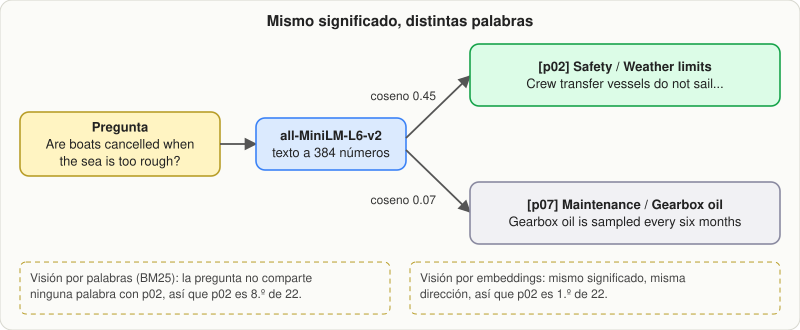

In [3]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))


diagram(800, 330, [
    ("box", 20, 112, 200, 64, "Pregunta\nAre boats cancelled when\nthe sea is too rough?", "gold"),
    ("arrow", 220, 144, 256, 144, ""),
    ("box", 256, 118, 150, 52, "all-MiniLM-L6-v2\ntexto a 384 números", "blue"),
    ("arrow", 406, 138, 470, 76, ""),
    ("text", 436, 100, "coseno 0.45", 12, "end"),
    ("arrow", 406, 150, 470, 212, ""),
    ("text", 436, 204, "coseno 0.07", 12, "end"),
    ("box", 470, 44, 310, 62, "[p02] Safety / Weather limits\nCrew transfer vessels do not sail...", "green"),
    ("box", 470, 182, 310, 62, "[p07] Maintenance / Gearbox oil\nGearbox oil is sampled every six months", "grey"),
    ("note", 20, 262, 370, 52, "Visión por palabras (BM25): la pregunta no comparte\nninguna palabra con p02, así que p02 es 8.º de 22."),
    ("note", 410, 262, 370, 52, "Visión por embeddings: mismo significado, misma\ndirección, así que p02 es 1.º de 22."),
], "Mismo significado, distintas palabras")

In [4]:
from sentence_transformers import SentenceTransformer
t0 = time.time()
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
print(f"model loaded in {time.time() - t0:.1f} s, {sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters, dimension {model.get_sentence_embedding_dimension()}")

t0 = time.time()
E = model.encode(chunks, normalize_embeddings=True)          # longitud unitaria, así que un producto escalar ES el coseno
print(f"embedded {len(chunks)} passages in {time.time() - t0:.2f} s -> matrix {E.shape}, {E.astype(np.float16).nbytes / 1024:.0f} KiB as float16")

def semantic_scores(query):
    return E @ model.encode(query, normalize_embeddings=True)

for a, b in [("Are boats cancelled when the sea is too rough?", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m"),
             ("Are boats cancelled when the sea is too rough?", "Gearbox oil is sampled every six months"),
             ("What does code PF-203 mean?", "A pitch system fault (code PF-203) usually means a low accumulator pressure")]:
    va, vb = model.encode([a, b], normalize_embeddings=True)
    print(f"cosine {va @ vb:5.2f}   {a!r} vs {b[:60]!r}")

~/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3567.65it/s]

/tmp/ipykernel_300328/4019971189.py:4: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"model loaded in {time.time() - t0:.1f} s, {sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters, dimension {model.get_sentence_embedding_dimension()}")


model loaded in 5.8 s, 23 M parameters, dimension 384


embedded 22 passages in 0.87 s -> matrix (22, 384), 16 KiB as float16
cosine  0.45   'Are boats cancelled when the sea is too rough?' vs 'Crew transfer vessels do not sail when the significant wave '
cosine  0.07   'Are boats cancelled when the sea is too rough?' vs 'Gearbox oil is sampled every six months'
cosine  0.55   'What does code PF-203 mean?' vs 'A pitch system fault (code PF-203) usually means a low accum'


La paráfrasis y el pasaje que la responde puntúan claramente más alto que la paráfrasis y un pasaje sin relación, aunque
casi no comparten palabras. Esa es toda la idea. Ahora, la prueba justa.

## 3. Léxica frente a semántica, en tres tipos de pregunta

Ejecutamos la misma evaluación del módulo 01 (hit@1, hit@3, MRR), ahora sobre tres conjuntos de preguntas.

In [5]:
def ranks_of(scorer, questions):
    out = []
    for _, question, gold in questions:
        order = [ids[i] for i in np.argsort(-scorer(question))]
        out.append(order.index(gold) + 1)
    return np.array(out)

def report(scorers):
    print(f"{'method':22s}" + "".join(f"{name:>34s}" for name in SETS))
    print(f"{'':22s}" + f"{'hit@1   hit@3    MRR':>34s}" * len(SETS))
    for label, scorer in scorers.items():
        row = f"{label:22s}"
        for questions in SETS.values():
            r = ranks_of(scorer, questions)
            row += f"{(r == 1).mean():>14.2f}{(r <= 3).mean():>8.2f}{(1 / r).mean():>8.2f}"
        print(row)

report({"BM25 (lexical)": bm25.scores, "MiniLM (semantic)": semantic_scores})

method                                     original (14)                  paraphrases (10)                   identifiers (5)
                                    hit@1   hit@3    MRR              hit@1   hit@3    MRR              hit@1   hit@3    MRR
BM25 (lexical)                  0.86    1.00    0.93          0.40    0.60    0.53          1.00    1.00    1.00


MiniLM (semantic)               0.93    1.00    0.96          0.90    1.00    0.95          0.80    1.00    0.87


Mira las columnas, no el promedio. La búsqueda semántica debería ganar en las **paráfrasis**: para eso se construyó.
Pero mira los **identificadores**: un modelo que aprendió *significado* no tiene motivo especial para tratar `PF-203` o
`YW-110` como claves exactas, mientras que BM25 trata un token raro como la señal más fuerte posible. Veamos qué
preguntas falla cada uno.

In [6]:
for name, questions in list(SETS.items())[1:]:
    print(name)
    for (qid, question, gold), rb, rs in zip(questions, ranks_of(bm25.scores, questions), ranks_of(semantic_scores, questions)):
        if rb > 1 or rs > 1:
            print(f"  {qid}  BM25 rank {rb:2d} | semantic rank {rs:2d}   {question}")

paraphrases (10)


  r01  BM25 rank  8 | semantic rank  1   Are boats cancelled when the sea is too rough?
  r02  BM25 rank  3 | semantic rank  1   Can I go up the tower alone to fix something?
  r03  BM25 rank  5 | semantic rank  1   How big are the blades?
  r04  BM25 rank 18 | semantic rank  1   Who do I call in the middle of the night about an accident?
  r08  BM25 rank 21 | semantic rank  1   Is the farm allowed to produce at full output?
  r10  BM25 rank  2 | semantic rank  2   How should rubbish and old oil be handled?
identifiers (5)
  e03  BM25 rank  1 | semantic rank  3   ISO 4406 18/16/13


## 4. Recuperación híbrida con Reciprocal Rank Fusion

Cada método falla en preguntas distintas, así que pregunta a ambos y fusiona las dos ordenaciones. La trampa es que las
puntuaciones **no son comparables**: las de BM25 van de 0 a quizá 15, los cosenos de 0 a 1. Normalizarlas y sumarlas es
frágil. **Reciprocal Rank Fusion (RRF)** esquiva las puntuaciones por completo y usa solo las *posiciones*:

$$\text{RRF}(d)=\sum_{\text{rankers}}\frac{1}{k+\text{rank}(d)}\qquad(k=60\text{ es la constante estándar})$$

Un pasaje cercano a la cabeza de cualquiera de las listas obtiene una puntuación fusionada alta, y uno cercano a la
cabeza de *ambas* obtiene la más alta. No necesita ajuste, ni entrenamiento, ni calibrar puntuaciones, y por eso es la
receta híbrida por defecto en la mayoría de los sistemas de búsqueda.

### Imagen: cómo dos clasificaciones se convierten en una

La primera pregunta parafraseada va a los dos clasificadores. Cada uno informa del puesto del pasaje correcto (p02) y
RRF convierte los dos puestos en una sola puntuación, con un peso para BM25. Las cuatro cajas de abajo son el
resultado medido de cambiar ese peso, sobre las diez preguntas parafraseadas de la tabla que verás a continuación.

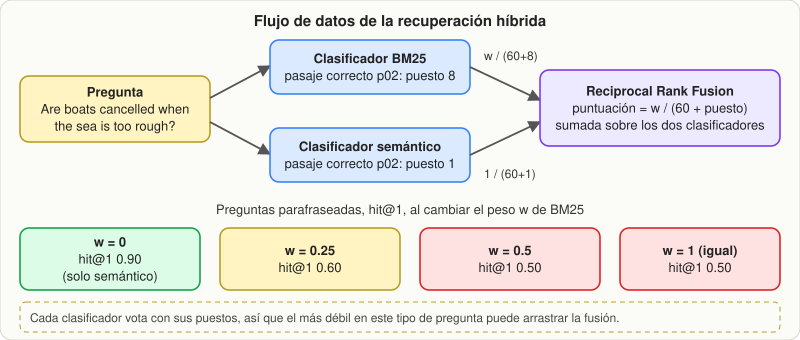

In [7]:
diagram(800, 340, [
    ("box", 20, 76, 190, 66, "Pregunta\nAre boats cancelled when\nthe sea is too rough?", "gold"),
    ("arrow", 210, 98, 270, 66, ""),
    ("arrow", 210, 122, 270, 154, ""),
    ("box", 270, 40, 200, 54, "Clasificador BM25\npasaje correcto p02: puesto 8", "blue"),
    ("box", 270, 128, 200, 54, "Clasificador semántico\npasaje correcto p02: puesto 1", "blue"),
    ("arrow", 470, 67, 540, 100, ""),
    ("text", 484, 60, "w / (60+8)", 12, "start"),
    ("arrow", 470, 155, 540, 122, ""),
    ("text", 484, 178, "1 / (60+1)", 12, "start"),
    ("box", 540, 70, 240, 76, "Reciprocal Rank Fusion\npuntuación = w / (60 + puesto)\nsumada sobre los dos clasificadores", "violet"),
    ("text", 400, 214, "Preguntas parafraseadas, hit@1, al cambiar el peso w de BM25", 13, "middle"),
    ("box", 20, 228, 180, 62, "w = 0\nhit@1 0.90\n(solo semántico)", "green"),
    ("box", 220, 228, 180, 62, "w = 0.25\nhit@1 0.60", "gold"),
    ("box", 420, 228, 180, 62, "w = 0.5\nhit@1 0.50", "red"),
    ("box", 620, 228, 160, 62, "w = 1 (igual)\nhit@1 0.50", "red"),
    ("note", 20, 302, 760, 30, "Cada clasificador vota con sus puestos, así que el más débil en este tipo de pregunta puede arrastrar la fusión."),
], "Flujo de datos de la recuperación híbrida")

In [8]:
def rrf(scorers, k=60, weights=None):
    weights = weights or [1.0] * len(scorers)
    def fused(query):
        total = np.zeros(len(ids))
        for scorer, w in zip(scorers, weights):
            order = np.argsort(-scorer(query))
            for rank, i in enumerate(order, start=1):
                total[i] += w / (k + rank)
        return total
    return fused

hybrid = rrf([bm25.scores, semantic_scores])
report({"BM25 (lexical)": bm25.scores, "MiniLM (semantic)": semantic_scores, "Hybrid (RRF)": hybrid})

method                                     original (14)                  paraphrases (10)                   identifiers (5)
                                    hit@1   hit@3    MRR              hit@1   hit@3    MRR              hit@1   hit@3    MRR
BM25 (lexical)                  0.86    1.00    0.93          0.40    0.60    0.53          1.00    1.00    1.00


MiniLM (semantic)               0.93    1.00    0.96          0.90    1.00    0.95          0.80    1.00    0.87


Hybrid (RRF)                    0.86    1.00    0.93          0.50    0.80    0.66          1.00    1.00    1.00


Lee esta tabla con cuidado, porque no dice lo que dicen los manuales. En este corpus el híbrido 50/50 simple arregla los
fallos de identificadores de la búsqueda semántica, pero en las paráfrasis **lo arrastra el ordenador más débil**: BM25
pone pasajes equivocados arriba en esas preguntas y la fusión con pesos iguales le cree. La fusión ayuda cuando ambos
ordenadores son aceptables y se equivocan en sitios *distintos*; no rescata a un ordenador que es simplemente malo en un
tipo entero de pregunta. El mando que importa es el **peso**. Barrido:

In [9]:
print("weight of BM25 relative to the semantic ranker (semantic weight = 1):")
report({f"BM25 weight {w:g}": rrf([bm25.scores, semantic_scores], weights=[w, 1.0]) for w in (0, 0.25, 0.5, 1.0)})

weight of BM25 relative to the semantic ranker (semantic weight = 1):
method                                     original (14)                  paraphrases (10)                   identifiers (5)
                                    hit@1   hit@3    MRR              hit@1   hit@3    MRR              hit@1   hit@3    MRR


BM25 weight 0                   0.93    1.00    0.96          0.90    1.00    0.95          0.80    1.00    0.87


BM25 weight 0.25                0.93    1.00    0.96          0.60    1.00    0.78          1.00    1.00    1.00


BM25 weight 0.5                 0.93    1.00    0.96          0.50    0.90    0.69          1.00    1.00    1.00


BM25 weight 1                   0.86    1.00    0.93          0.50    0.80    0.66          1.00    1.00    1.00


Bajar el peso de BM25 cambia una debilidad por la otra: con 0.25 las preguntas de identificadores vuelven a salir bien y
el MRR de las paráfrasis se recupera en parte (0.78, frente a 0.66 con pesos iguales y 0.95 del ordenador semántico
solo), pero ningún ajuste de aquí es el mejor en todos los conjuntos. Con solo 29 preguntas las diferencias entre
números cercanos están dentro del ruido, así que no copies un peso de esta tabla: **ajústalo con tus propias preguntas**
(el módulo 07 muestra cómo construir y dimensionar esa evaluación) y vuelve a comprobarlo cada vez que cambie el corpus
o el modelo de embeddings.

## 5. Negarse a responder con puntuaciones de embeddings

Con BM25, una puntuación de cero significaba "ninguna palabra en común". Las puntuaciones de coseno nunca llegan a cero
(todo se parece un poco a todo), así que el umbral de rechazo hay que leerlo de los datos otra vez, usando las dos
preguntas sin respuesta más algunas ajenas al tema.

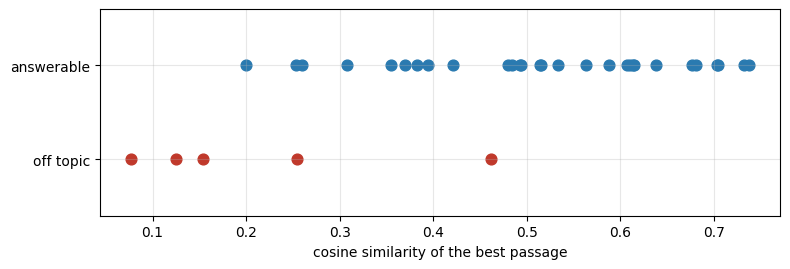

answerable: lowest 0.20   off-topic: highest 0.46


In [10]:
off_topic = ["What is the price of electricity per MWh?", "Who is the chief executive of the operating company?",
             "What is the best pasta recipe?", "How do I reset my email password?", "Who won the football match yesterday?"]
best_off = [semantic_scores(q).max() for q in off_topic]
best_on = [semantic_scores(q[1]).max() for qs in SETS.values() for q in qs]

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.scatter(best_on, np.ones(len(best_on)), s=60, color="#2a7ab0", label="answerable")
ax.scatter(best_off, np.zeros(len(best_off)), s=60, color="#c0392b", label="not in the handbook")
ax.set_yticks([0, 1], ["off topic", "answerable"]); ax.set_xlabel("cosine similarity of the best passage"); ax.set_ylim(-.6, 1.6); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"answerable: lowest {min(best_on):.2f}   off-topic: highest {max(best_off):.2f}")

Los dos grupos **se solapan** aquí (la puntuación más baja con respuesta es menor que la más alta fuera de tema), así
que ningún umbral único es correcto: subirlo rechaza preguntas reales, bajarlo responde disparates. Una respuesta
habitual en producción es *no decidir aquí*: mantener un umbral permisivo, dejar que el generador vea los pasajes y que
el generador (y más tarde el supervisor del módulo 08) diga "los documentos no contienen esto". La recuperación
propone; la etapa de respuesta y el evaluador deciden.

## 6. ¿Cuándo hace falta un índice vectorial?

Comparamos el vector de la pregunta con los 22 vectores de pasajes, una búsqueda de *fuerza bruta*. Es exacta y, a este
tamaño, instantánea. Existen bibliotecas como **FAISS** (usada por otro proyecto de este portfolio), pgvector o bases
de datos vectoriales gestionadas para corpus donde la fuerza bruta se queda lenta: cambian un poco de exactitud por una
búsqueda de vecinos más cercanos *aproximada* mucho más rápida. Mide antes de adoptar una:

In [11]:
rng = np.random.default_rng(0)
dim = E.shape[1]
for n in (1_000, 10_000, 100_000):
    M = rng.standard_normal((n, dim)).astype(np.float32)
    M /= np.linalg.norm(M, axis=1, keepdims=True)
    q = M[0]
    t0 = time.perf_counter()
    for _ in range(20):
        top = np.argpartition(-(M @ q), 5)[:5]
    ms = (time.perf_counter() - t0) / 20 * 1000
    print(f"{n:>9,d} vectors: {ms:7.2f} ms per brute-force query, {M.nbytes / 1e6:6.0f} MB in float32")

    1,000 vectors:    0.09 ms per brute-force query,      2 MB in float32
   10,000 vectors:    1.22 ms per brute-force query,     15 MB in float32


  100,000 vectors:    7.64 ms per brute-force query,    154 MB in float32


La fuerza bruta escala de forma lineal: diez veces más vectores, diez veces más tiempo. Unos pocos miles de trozos son
milisegundos, y una aplicación que sirva unos cientos de miles de trozos en una CPU sigue dentro de un presupuesto
interactivo. La decisión de adoptar un índice aproximado depende, por tanto, del **tamaño del corpus y del volumen de
consultas**, no de la moda; por debajo de unos cien mil trozos, una matriz de NumPy enviada como un solo archivo (en
`float16` ocupa la mitad) es más simple de desplegar, probar y mantener correcta. Esa misma lógica hizo que dos
componentes de recuperación de este portfolio eligieran FAISS en proceso o BM25 sin más, en vez de un servidor de base
de datos siempre encendido.

## Ejercicios

1. Añade cinco paráfrasis tuyas y una pregunta de identificador. ¿Dónde falla cada método?
2. Cambia la constante `k` de RRF a 5 y a 500. ¿Qué tan sensible es el híbrido?
3. Dale a BM25 un peso de 2 en `rrf`. ¿Qué conjunto gana, cuál pierde, y cómo sabrías en producción hacia qué lado
   girar el mando sin una batería etiquetada?
4. Calcula el embedding de `section + text` frente a `text` solo. ¿Ayuda poner el título de la sección en el texto
   incrustado?